In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset

In [77]:
emotion_dataset=load_dataset('dair-ai/emotion')
train_text=emotion_dataset['train']['text']
train_label=emotion_dataset['train']['label']
test_text=emotion_dataset['test']['text']
test_label=emotion_dataset['test']['label']

In [78]:
label_names = emotion_dataset['train'].features['label'].names

In [79]:
for i in train_label:
  print(label_names[i])

Streaming output truncated to the last 5000 lines.
sadness
sadness
anger
fear
love
joy
anger
sadness
sadness
joy
fear
joy
fear
love
love
anger
anger
sadness
fear
sadness
sadness
surprise
love
joy
joy
love
sadness
joy
joy
fear
sadness
anger
anger
sadness
love
fear
fear
anger
anger
joy
sadness
sadness
joy
joy
fear
sadness
joy
love
fear
anger
sadness
joy
anger
surprise
fear
joy
joy
love
fear
sadness
joy
anger
fear
anger
sadness
sadness
sadness
anger
sadness
fear
joy
anger
anger
sadness
fear
joy
anger
fear
sadness
joy
fear
joy
love
anger
fear
fear
fear
fear
joy
anger
anger
sadness
joy
sadness
joy
sadness
sadness
joy
sadness
fear
fear
joy
sadness
joy
sadness
joy
fear
anger
sadness
joy
anger
joy
joy
sadness
joy
joy
anger
anger
joy
joy
joy
sadness
joy
joy
joy
anger
anger
joy
love
joy
love
joy
joy
joy
sadness
joy
sadness
surprise
sadness
anger
anger
anger
fear
fear
joy
fear
fear
joy
anger
joy
joy
joy
love
joy
fear
sadness
sadness
surprise
sadness
sadness
anger
joy
love
fear
joy
anger
joy
surpr

In [80]:
df_train=pd.DataFrame(
    {
        'text':train_text,
        'label':[label_names[i] for i in train_label]
    }
)
df_test=pd.DataFrame(
    {
        'text' : test_text,
        'label': [label_names[i] for i in test_label]
    }
)



In [81]:
df_train.isnull().sum()


,0
text,0
label,0


**EDA**

In [82]:
df_train['label'].value_counts().index

Index(['joy', 'sadness', 'anger', 'fear', 'love', 'surprise'], dtype='object', name='label')

<Axes: xlabel='label', ylabel='count'>

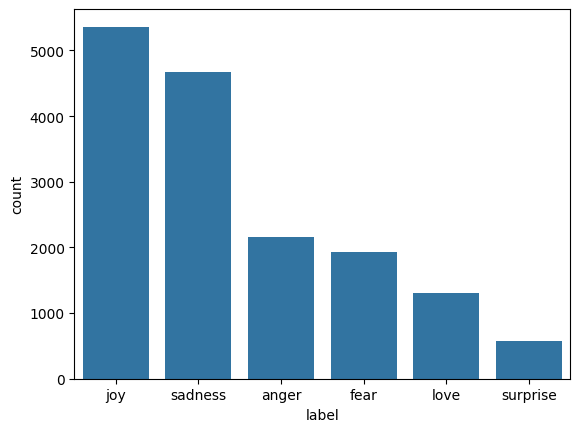

In [83]:
sns.countplot(x='label', data=df_train, order=df_train['label'].value_counts().index)

Preprocessing using NLP

In [91]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words=10000

tokenizer=Tokenizer(num_words=max_words, oov_token='')
tokenizer.fit_on_texts(df_train['text'])

train_sequences= tokenizer.texts_to_sequences(df_train['text'])
test_sequences= tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequence= pad_sequences(train_sequences,maxlen=50,padding='post',truncating='post')
padded_test_sequence= pad_sequences(test_sequences,maxlen=50,padding='post',truncating='post')

train_labels=np.array(train_label)
test_labels=np.array(test_label)

num_classes=len(np.unique(train_labels))
print(num_classes)

print(f"Vocabulary Size: {len(tokenizer.word_index)}")
print(f"Max Sentence Length: {padded_train_sequence.shape[1]}")

6
Vocabulary Size: 15213
Max Sentence Length: 50


In [85]:
from sklearn.utils import class_weight
class_weights =class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_label),
    y = train_labels
)
class_weight_dict = dict(enumerate(class_weights))

In [86]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)


In [87]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Embedding ,Dense, Dropout, LSTM, GRU

rnn_model=Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=50),
    SimpleRNN(units=128, return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(units=num_classes,activation='softmax')
])
rnn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy',metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [90]:
rnn_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)
rnn_loss, rnn_accuracy = rnn_model.evaluate(padded_test_sequence, test_labels)
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 28s 47ms/step - accuracy: 0.1601 - loss: 2.0811 - val_accuracy: 0.1115 - val_loss: 1.7483
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 23s 46ms/step - accuracy: 0.1452 - loss: 1.8862 - val_accuracy: 0.1520 - val_loss: 1.7940
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 42s 48ms/step - accuracy: 0.1388 - loss: 1.8242 - val_accuracy: 0.1090 - val_loss: 1.7343
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.1324 - loss: 1.8064 - val_accuracy: 0.0560 - val_loss: 1.8383
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.1459 - loss: 1.8047 - val_accuracy: 0.2660 - val_loss: 1.7614
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 24s 48ms/step - accuracy: 0.1472 - loss: 1.8009 - val_accuracy: 0.2725 - val_loss: 1.7684
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.1090 - loss: 1.7343
RNN Loss: 1.7342787981033325
RNN Accuracy: 0.10899999737739563


In [97]:
lstm_model=Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=50),
    LSTM(units=128, return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes,activation='softmax')
])
lstm_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy',metrics=['accuracy'])

lstm_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)
lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_sequence, test_labels)
print(f"LSTM Loss: {lstm_loss}")
print(f"LSTM Accuracy: {lstm_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 67s 128ms/step - accuracy: 0.1618 - loss: 1.7953 - val_accuracy: 0.2905 - val_loss: 1.7813
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 61s 122ms/step - accuracy: 0.1449 - loss: 1.7936 - val_accuracy: 0.1115 - val_loss: 1.7972
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 61s 123ms/step - accuracy: 0.1666 - loss: 1.7930 - val_accuracy: 0.0790 - val_loss: 1.7945
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.2905 - loss: 1.7813
LSTM Loss: 1.7812989950180054
LSTM Accuracy: 0.2904999852180481


In [95]:
gru_model=Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=50),
    GRU(units=128, return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes,activation='softmax')
])
gru_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy',metrics=['accuracy'])

gru_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)
gru_loss, gru_accuracy = gru_model.evaluate(padded_test_sequence, test_labels)
print(f"GRU Loss: {gru_loss}")
print(f"GRU Accuracy: {gru_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 56s 105ms/step - accuracy: 0.1499 - loss: 1.7960 - val_accuracy: 0.0330 - val_loss: 1.8087
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 53s 106ms/step - accuracy: 0.1440 - loss: 1.7956 - val_accuracy: 0.0845 - val_loss: 1.7806
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 52s 104ms/step - accuracy: 0.1525 - loss: 1.7933 - val_accuracy: 0.2875 - val_loss: 1.7693
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.0330 - loss: 1.8087
GRU Loss: 1.8086506128311157
GRU Accuracy: 0.032999999821186066


In [98]:
from tensorflow.keras.layers import Bidirectional

BiGRU= Sequential([
    Embedding(input_dim=max_words, output_dim=300, input_length=50),
    Bidirectional(GRU(128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])
BiGRU.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

BiGRU.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_9 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [99]:
BiGRU.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

BiGRU_loss, BiGRU_accuracy = BiGRU.evaluate(padded_test_sequence, test_labels)
print(f"BiGRU Loss: {BiGRU_loss}")
print(f"BiGRU Accuracy: {BiGRU_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 158s 301ms/step - accuracy: 0.5693 - loss: 1.0278 - val_accuracy: 0.8855 - val_loss: 0.3842
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 147s 294ms/step - accuracy: 0.9171 - loss: 0.2409 - val_accuracy: 0.9110 - val_loss: 0.2530
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 202s 295ms/step - accuracy: 0.9421 - loss: 0.1534 - val_accuracy: 0.9135 - val_loss: 0.2434
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 203s 297ms/step - accuracy: 0.9593 - loss: 0.1139 - val_accuracy: 0.9175 - val_loss: 0.2715
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 201s 296ms/step - accuracy: 0.9661 - loss: 0.0924 - val_accuracy: 0.9200 - val_loss: 0.2554
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 150s 301ms/step - accuracy: 0.9744 - loss: 0.0738 - val_accuracy: 0.9250 - val_loss: 0.2561
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 58ms/step - accuracy: 0.9135 - loss: 0.2434
BiGRU Loss: 0.24341556429862976
BiGRU Accuracy: 0.9135000109672546


63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 73ms/step


<Axes: >

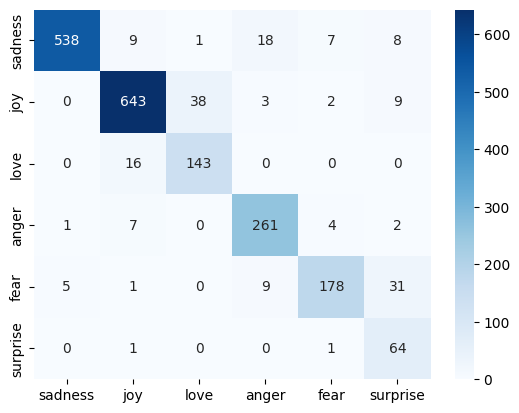

In [101]:
from sklearn.metrics import confusion_matrix
BiGRU_prediction=np.argmax(BiGRU.predict(padded_test_sequence),axis=1)
sns.heatmap(confusion_matrix(test_label,BiGRU_prediction),annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)

In [102]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')

sample_predictions = np.argmax(BiGRU.predict(sample_padded_sequences), axis=1)

for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_names[sample_predictions[i]]}')


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: surprise
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise


In [103]:
import os
import pickle

model_dir = 'Artifacts'
os.makedirs(model_dir, exist_ok=True) #yeh folder hai jiske andar sari exported file aane wali hai

#Save our BiGRU Model
BiGRU.save(os.path.join(model_dir, 'BiGRU_Modle.keras'))

#Save the tokenizer model
with open(os.path.join(model_dir, 'tokenizer.pkl'), 'wb') as file:
  pickle.dump(tokenizer, file)
